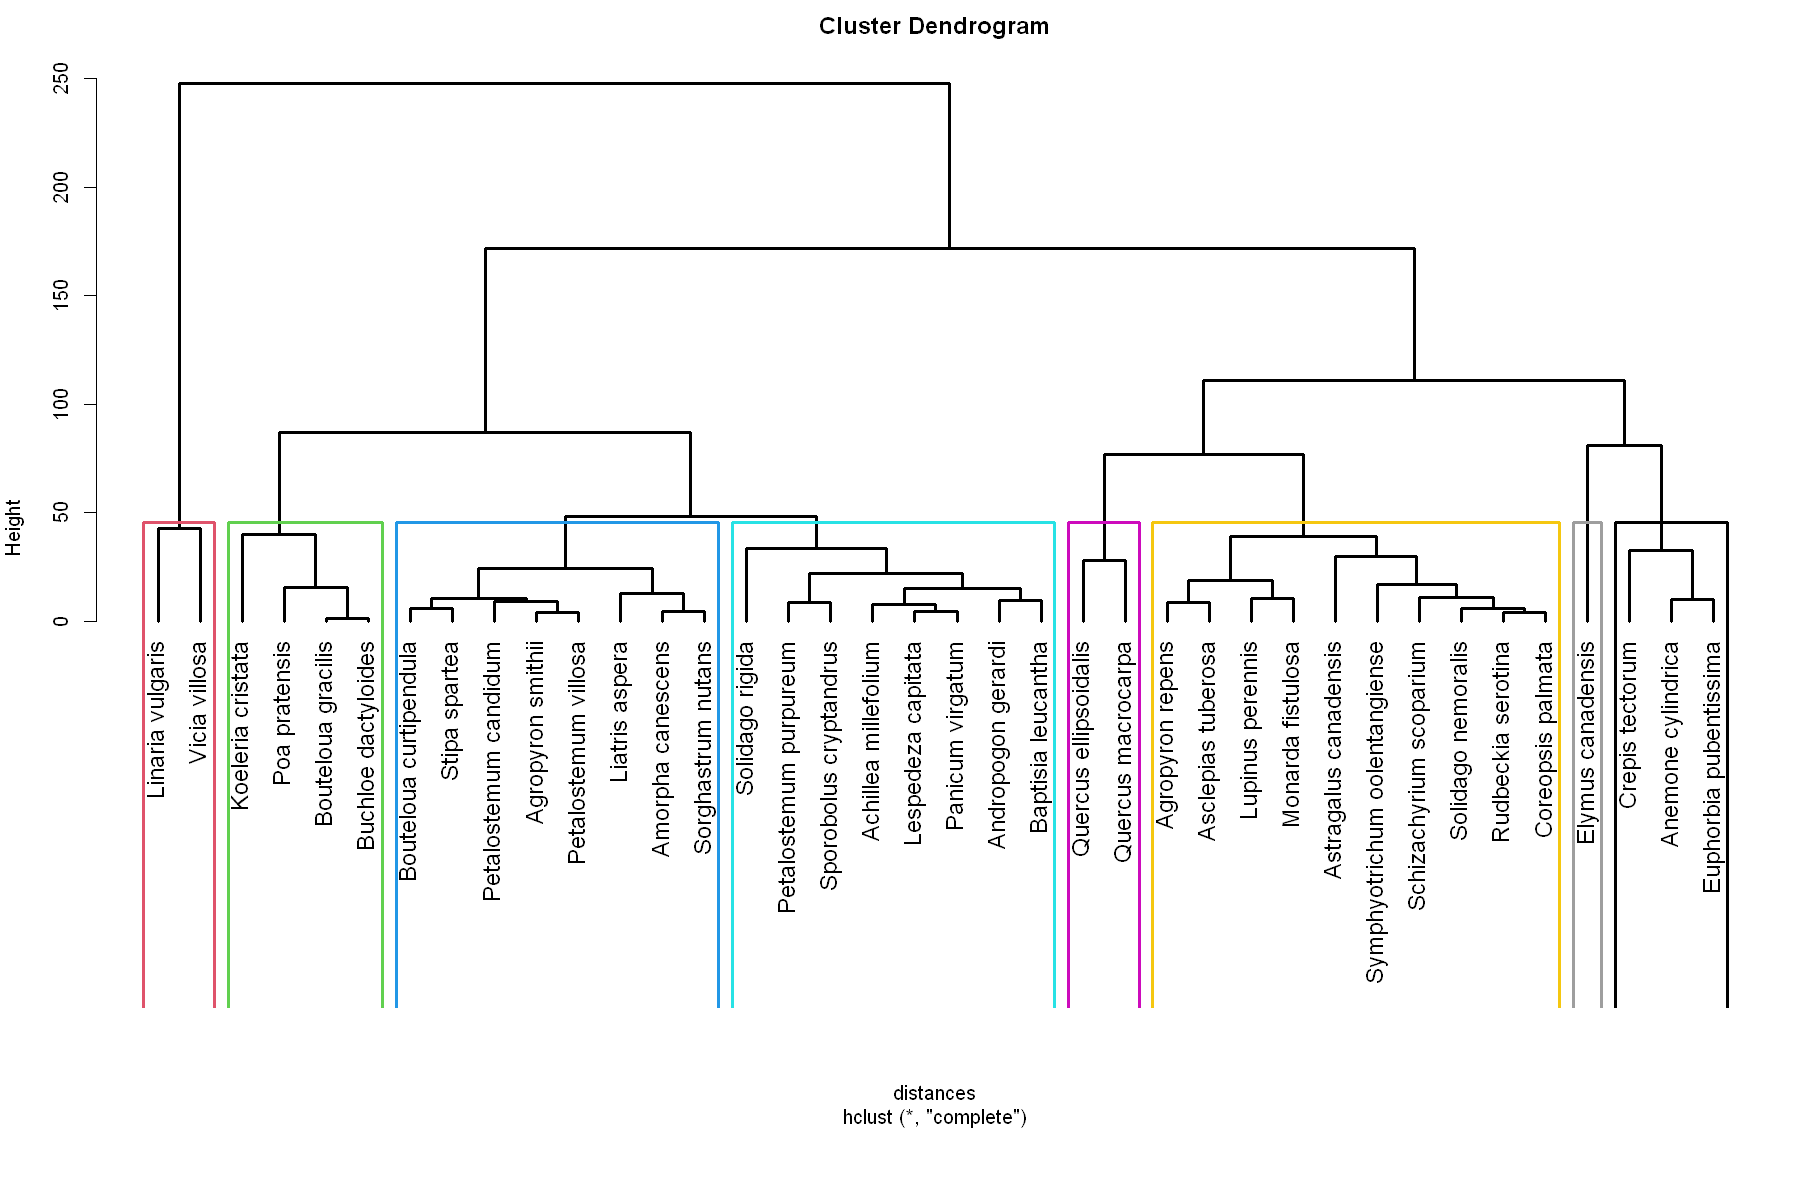

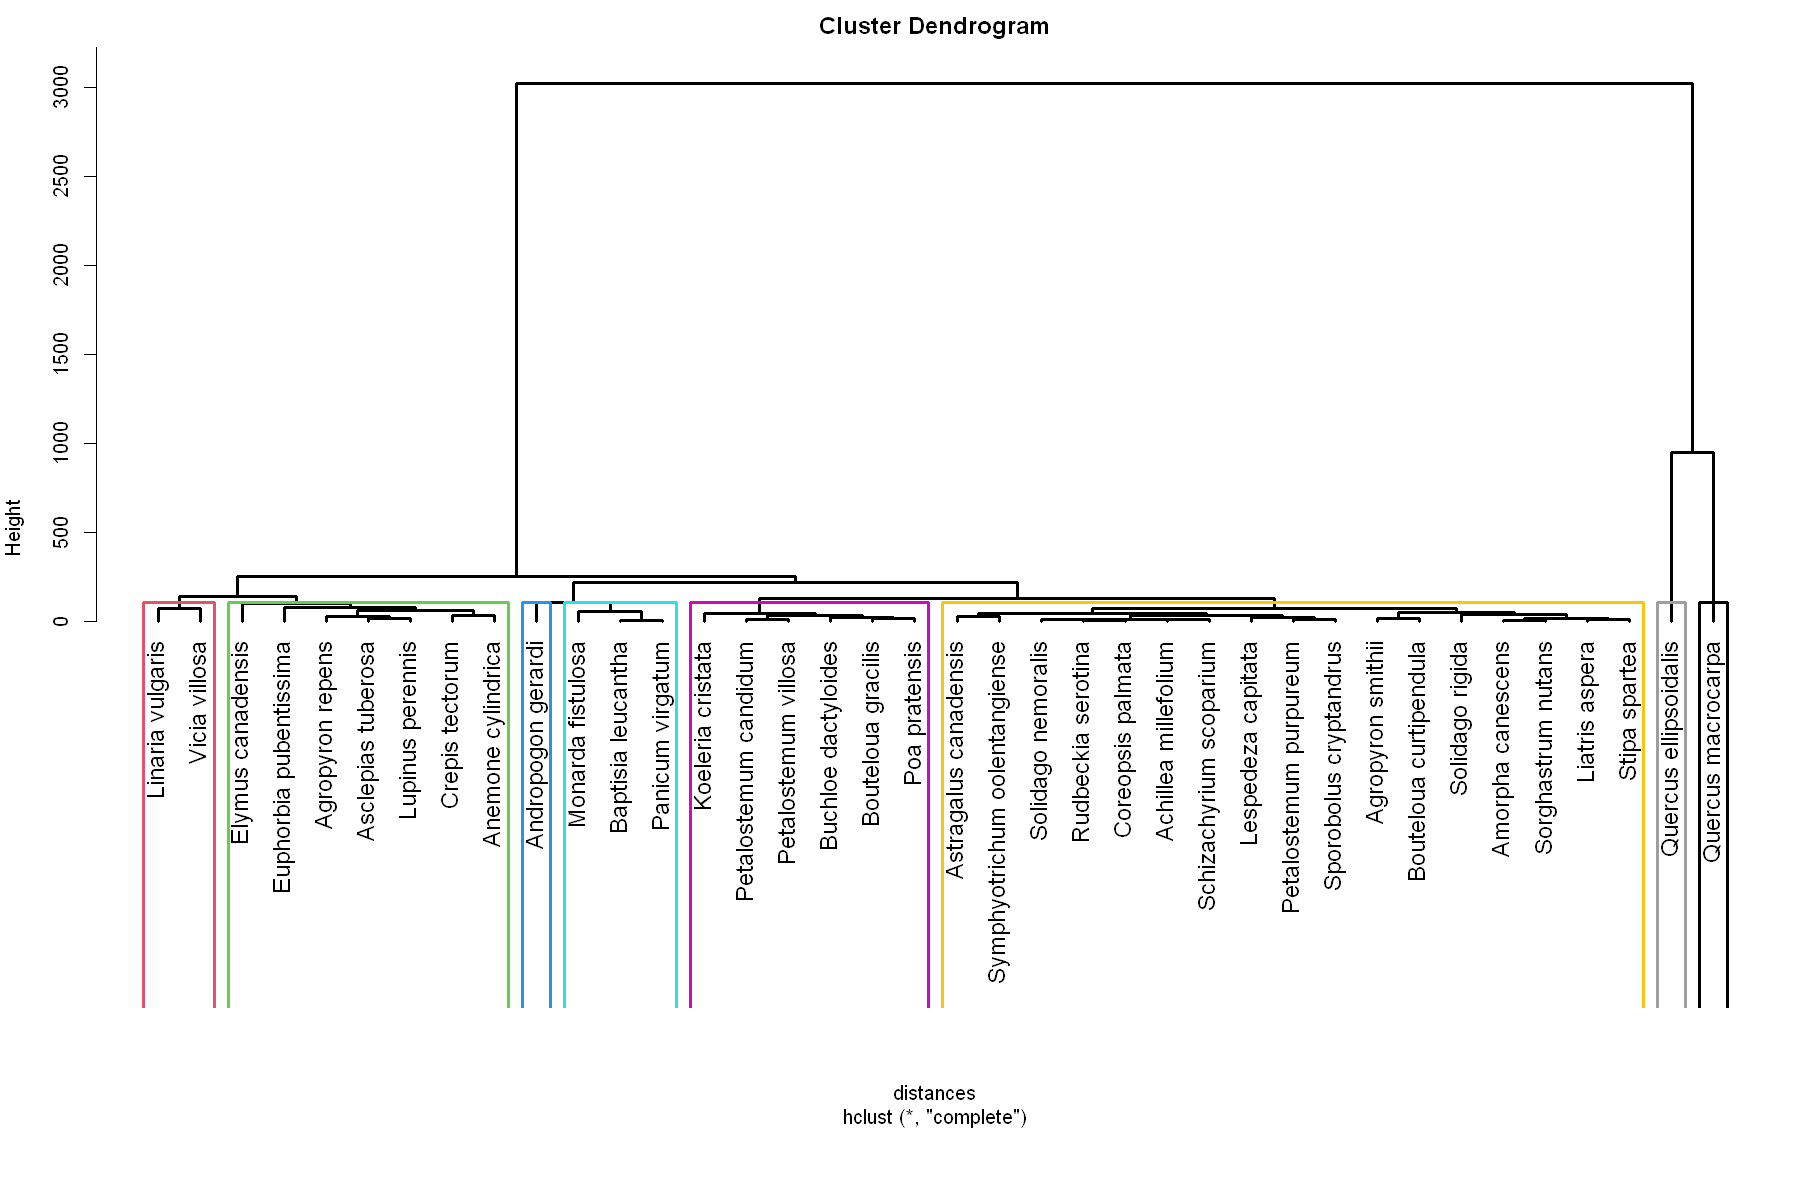

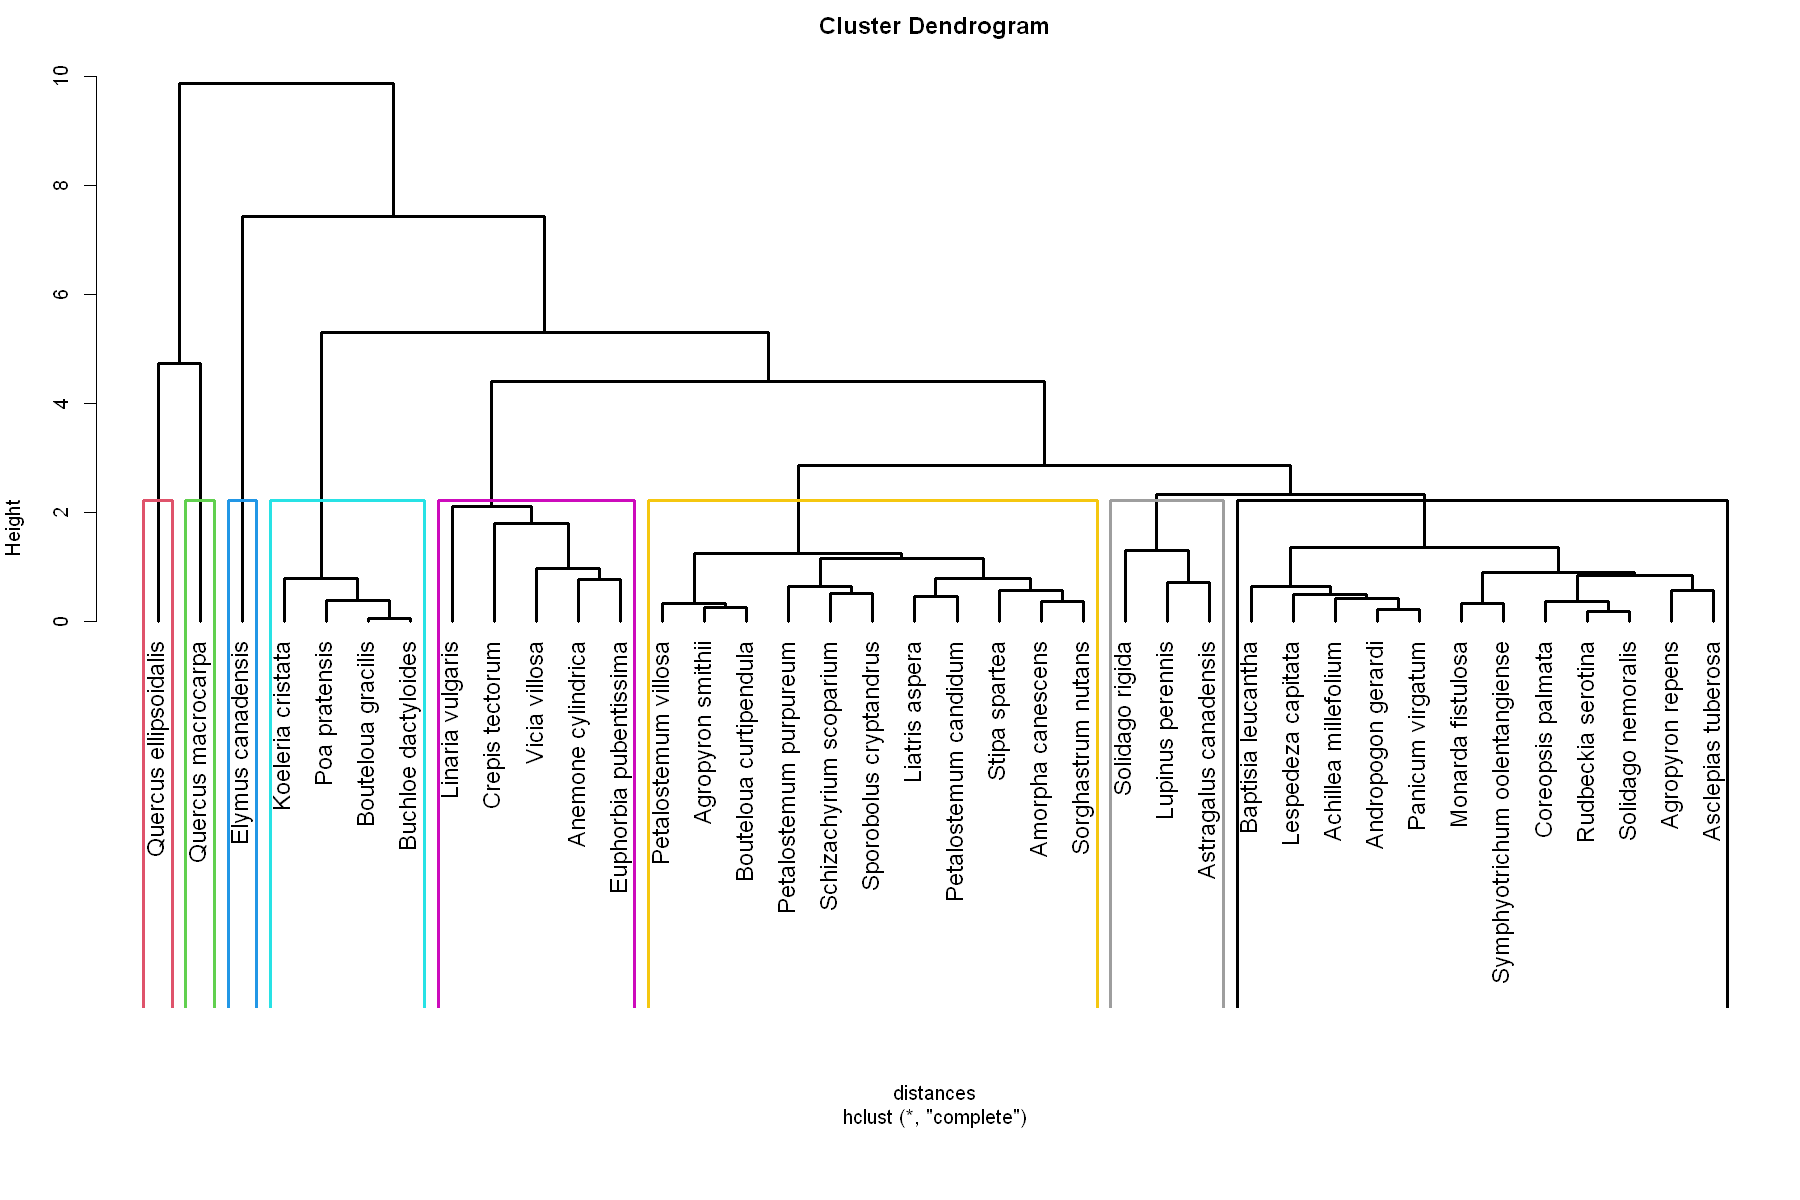

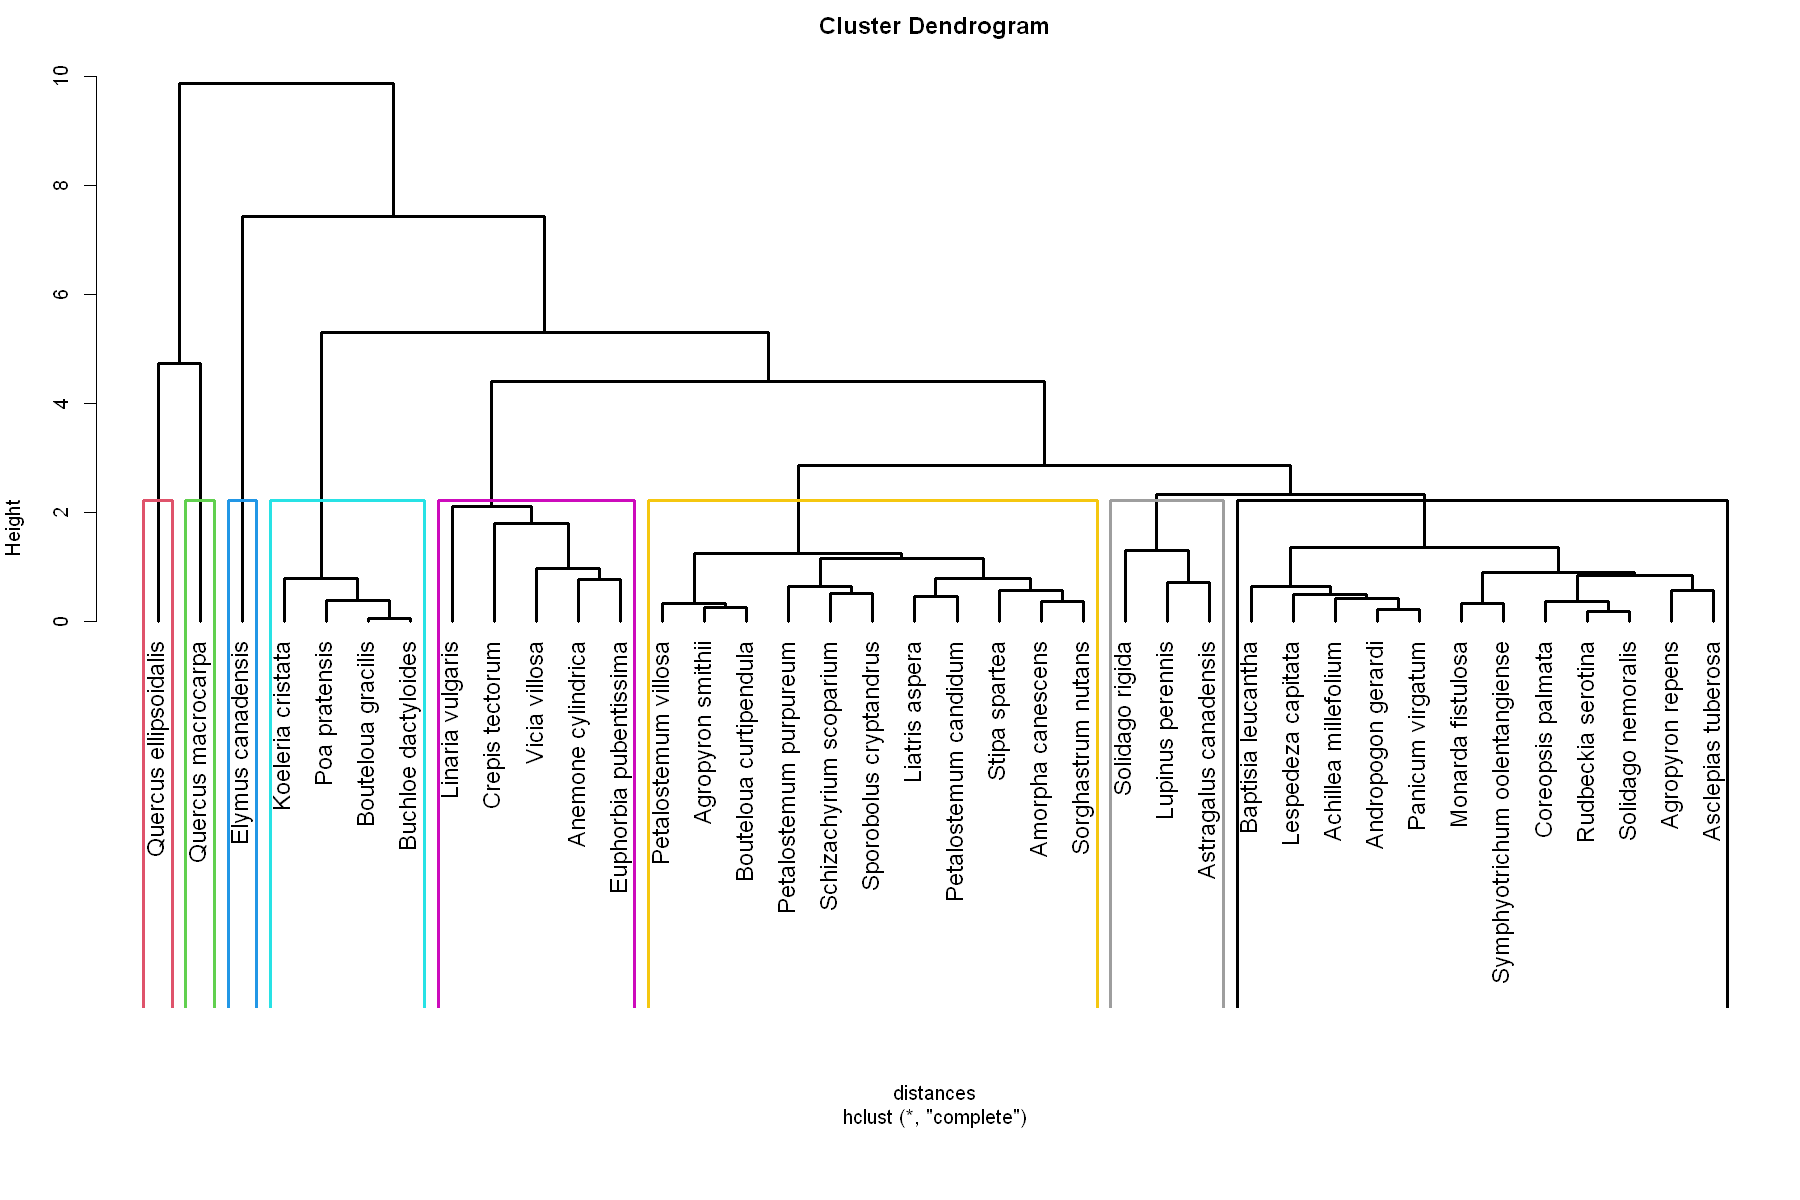

In [111]:
options(repr.plot.width = 15, repr.plot.height = 10)
rm(list = ls())

library(dendextend)

# Import dataset
setwd("C:/Users/ronan/Desktop/Final Year Project/clustering-functional-groups/")
traits <- read.csv("e120_Plant traits.csv", header = TRUE, sep = ",")

# Rename covariates for simplicity
new_names <- c("year", "species", "leaf_area", "perim_area", "perim_area_length", "spec_leaf_area", "seed_weight", "height")
names(traits) <- new_names

hierarchical_cluster = function(df, rescale, linkage) {
  dataset <- df
  if (rescale == 1){
    dataset <- scale(dataset)
  }
  distances <- dist(dataset, method = "euclidean")
  hc <- hclust(distances, method = linkage)
  return(hc)
}

pair_species_with_cluster = function(c1, c2) {
  df <- data.frame(
    species = c1,
    cluster_id = c2
  )
  return(df)
}

plot_dendrogram = function(hc, k) {
  par(mar = c(8, 4, 2, 1), lwd = 3)
    plot(hc, hang = -1, labels = traits$species, cex = 1.2)
    rect.hclust(hc, k = k, border = 2:(k+1)) # add borders around
    clusters <- cutree(hc, k = k)
}


num_clusters = 8

o1 <- hierarchical_cluster(traits[, 3:8], 0, "complete")
o2 <- hierarchical_cluster(traits[, 3:8], 1, "complete")


traits$height <- traits$height *  100
o3 <- hierarchical_cluster(traits[, 3:8], 0, "complete")
o4 <- hierarchical_cluster(traits[, 3:8], 1, "complete")

plot_dendrogram(o1, num_clusters)
plot_dendrogram(o3, num_clusters)
plot_dendrogram(o2, num_clusters)
plot_dendrogram(o4, num_clusters)
